# 01 · El rol: quién es el agente

## El mapa del seminario

Vamos a construir cuatro cosas. En un framework de «cadenas» viven escondidas dentro de
una caja negra; en LangGraph son **objetos que se ven dibujados en el grafo**:

| Concepto | Dónde vive en LangGraph | Cómo se ve |
|---|---|---|
| **Rol** | el prompt de sistema de un nodo | la función que escribes |
| **Herramientas** | `ToolNode` + una arista condicional | un nodo y una flecha |
| **Memoria** | `checkpointer` + `thread_id` (corto plazo) · `Store` (largo plazo) | lo que pasas en `config` |
| **Planificación** | las aristas agente y herramientas | el grafo que dibujas |

Empezamos por el rol, porque es lo que convierte una llamada a un LLM en un *agente*:
alguien con identidad, con un objetivo y con límites.

## 1.1 El grafo más pequeño posible

Antes de hablar de roles hay que ver qué es un grafo en LangGraph. Son tres piezas:

* **Estado** (`MessagesState`): el sobre que viaja entre nodos. Aquí, la lista de mensajes.
* **Nodo**: una función que recibe el estado y devuelve **solo lo que cambia**.
* **Aristas**: quién va después de quién.

Ese detalle del nodo es importante y sorprende al principio: un nodo no devuelve el
estado completo, devuelve el parche. LangGraph lo fusiona con el estado anterior.

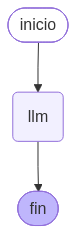

---
config:
 flowchart:
  curve: linear
---
graph TD;
	__start__([inicio]):::first
	llm(llm)
	__end__([fin]):::last
	__start__ --> llm;
	llm --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc


[grafo] Grafo 1: el más pequeño  ·  guardado en grafos/grafo-1-el-mas-pequeno.mmd


In [1]:
from langgraph.graph import StateGraph, START, END, MessagesState
import comun

modelo = comun.llm()

def nodo_llm(estado: MessagesState):
    # Recibe el estado entero, devuelve SOLO la clave que modifica.
    return {"messages": [modelo.invoke(estado["messages"])]}

constructor = StateGraph(MessagesState)
constructor.add_node("llm", nodo_llm)
constructor.add_edge(START, "llm")
constructor.add_edge("llm", END)
grafo = constructor.compile()

comun.ver_grafo(grafo, "Grafo 1: el más pequeño")


Ese texto es el grafo en notación [Mermaid](https://mermaid.live). Pégalo ahí y lo verás
como diagrama. Esta es la ventaja didáctica de LangGraph: **la estructura es un dato**,
no algo que hay que imaginar. Vamos a ejecutarlo.

In [2]:
resultado = grafo.invoke({"messages": [{"role": "user", "content": "¿Quién eres?"}]})
print(resultado["messages"][-1].content[:400])


Soy un modelo de lenguaje grande, entrenado por Google.

En términos sencillos, soy una inteligencia artificial diseñada para procesar información, responder preguntas, redactar textos, traducir idiomas y ayudarte con diversas tareas creativas o técnicas. No tengo cuerpo, sentimientos ni conciencia, pero puedo analizar grandes cantidades de datos para ofrecerte respuestas útiles y coherentes.

¿En


## 1.2 El rol es un parámetro, no una constante

Fíjate en lo que acabamos de ver: el modelo no tenía rol, así que respondió como
«un asistente cualquiera». Ahora viene la primera ventaja de LangGraph: el rol **no** es
una cadena escondida dentro de una clase. Es un dato que pasas al construir el grafo.

Vamos a fabricar el mismo grafo con dos roles distintos y hacerles la misma pregunta.

In [3]:
from langchain_core.messages import SystemMessage

def crear_agente_con_rol(rol: str):
    """Devuelve un grafo cuyo único nodo encarna ese rol."""
    def nodo(estado: MessagesState):
        mensajes = [SystemMessage(content=rol)] + estado["messages"]
        return {"messages": [modelo.invoke(mensajes)]}

    c = StateGraph(MessagesState)
    c.add_node("agente", nodo)
    c.add_edge(START, "agente")
    c.add_edge("agente", END)
    return c.compile()

PREGUNTA = "Tengo pollo, arroz y espinacas. ¿Qué hago?"

ROLES = {
    "Chef creativo": (
        "Eres un chef mediterráneo. Propones platos sabrosos y rápidos. "
        "Hablas de cocina, de texturas y de trucos."
    ),
    "Nutricionista": (
        "Eres un nutricionista deportivo. Te importan las calorías y los macronutrientes. "
        "Das siempre cifras concretas."
    ),
}

for nombre, rol in ROLES.items():
    salida = crear_agente_con_rol(rol).invoke(
        {"messages": [{"role": "user", "content": PREGUNTA}]}
    )
    print("=" * 72)
    print(nombre.upper())
    print("=" * 72)
    print(salida["messages"][-1].content[:420])
    print()


CHEF CREATIVO
¡Hola! Qué alegría saludarte. Tienes tres ingredientes básicos, pero con el toque mediterráneo vamos a convertirlos en un plato reconfortante, vibrante y, sobre todo, rápido.

No quiero que hagas el típico arroz hervido sin gracia. Vamos a buscar **texturas**: que el pollo quede jugoso y el arroz tenga ese saborcito a sofrito que enamora.

Te propongo un **"Arroz Meloso de Pollo y Espinacas al Ajillo"**.

### 🥘 El Pl



NUTRICIONISTA
Como nutricionista deportivo, voy a optimizar estos ingredientes para crear una comida equilibrada, ideal para la recuperación muscular y el llenado de glucógeno.

La mejor opción es un **Bowl de Pollo Salteado con Arroz y Espinacas**.

Aquí tienes la preparación y el desglose nutricional exacto para una ración estándar de rendimiento:

### Preparación:
1. **Arroz:** Cocina 80g de arroz en seco (pesado antes de cocer



## 1.3 El rol da **contenido**, pero no garantiza la **forma**

Un rol bien escrito orienta el tono, el enfoque y el vocabulario. Lo que **no** hace es
obligar al modelo a devolver una estructura concreta.

Vamos a comprobarlo de la forma más honesta posible: pidiéndolo por favor y contando
cuántas veces nos hace caso de tres intentos.

In [4]:
import json
from pydantic import BaseModel, Field

class Receta(BaseModel):
    titulo: str = Field(description="Nombre del plato")
    minutos: int = Field(description="Tiempo total de preparación, en minutos")
    ingredientes: list[str] = Field(description="Ingredientes necesarios")

esquema = json.dumps(Receta.model_json_schema(), ensure_ascii=False)
peticion = (
    "Devuelve ÚNICAMENTE un objeto JSON válido, sin markdown ni texto adicional, "
    "que cumpla exactamente este JSON Schema:\n"
    f"{esquema}\n\n"
    "Receta rápida con pollo."
)
INSTANCIA = "Eres un chef. Cuando se te pide un formato, lo obedeces al pie de la letra."

validos = 0
for intento in range(1, 4):
    crudo = modelo.invoke([("system", INSTANCIA), ("human", peticion)]).content
    try:
        Receta.model_validate_json(crudo)
        validos += 1
        print(f"intento {intento}: JSON válido")
    except Exception as error:
        print(f"intento {intento}: NO válido ({type(error).__name__})")
        if intento == 1:
            print("   esto es lo que devolvió de verdad:")
            print("   " + crudo[:200].replace("\n", "\n   "))

print()
print(f"RESULTADO: {validos} de 3 intentos devolvieron JSON válido.")
print("Pedir el formato «por favor» no es un contrato: es una sugerencia.")


intento 1: JSON válido


intento 2: JSON válido


intento 3: JSON válido

RESULTADO: 3 de 3 intentos devolvieron JSON válido.
Pedir el formato «por favor» no es un contrato: es una sugerencia.


## 1.4 La forma se impone por el **canal de herramientas**

Para conseguir una estructura garantizada hay que dejar de pedir y empezar a **obligar**.
`create_agent` acepta `response_format=` con un modelo de Pydantic.

Por debajo no hay magia: LangChain construye una **herramienta** cuyo esquema es tu modelo
de Pydantic y le exige al modelo rellenarla. Es exactamente el mismo mecanismo que
estudiaremos en el módulo de herramientas. Ese es el motivo de que este módulo vaya antes:
el rol te da el *qué*, y el canal de herramientas te da el *cómo*, con garantías.

In [5]:
from langchain.agents import create_agent

agente = create_agent(
    modelo,
    tools=[],                      # todavía no hay herramientas propias
    system_prompt="Eres un chef mediterráneo. Propones platos rápidos y sabrosos.",
    response_format=Receta,        # <- el contrato de formato
)

salida = agente.invoke({"messages": [{"role": "user", "content": "Receta rápida con pollo."}]})

print("claves del estado devuelto:", list(salida.keys()))
receta = salida["structured_response"]
print("tipo devuelto:", type(receta).__name__)
print()
print("titulo      :", receta.titulo)
print("minutos     :", receta.minutos)
print("ingredientes:", receta.ingredientes)


claves del estado devuelto: ['messages', 'structured_response']
tipo devuelto: Receta

titulo      : Pollo Mediterráneo al Limón y Ajo
minutos     : 15
ingredientes: ['2 pechugas de pollo cortadas en dados', 'El zumo de 1 limón', '2 dientes de ajo picados', '1 cucharada de aceite de oliva virgen extra', 'Perejil fresco picado', 'Sal y pimienta negra al gusto', 'Opcional: una pizca de orégano seco']


## 1.5 Un rol que se puede **verificar**

Un rol serio no es solo una personalidad: son **restricciones comprobables**. Aquí le
exigimos al agente que ninguna receta pase de 15 minutos, y lo comprobamos con Python.

La diferencia es enorme. Si el rol solo vive en el prompt, un incumplimiento lo descubre
el usuario. Si además lo verificamos, lo descubrimos nosotros.

In [6]:
LIMITE = 15

agente_express = create_agent(
    modelo,
    tools=[],
    system_prompt=(
        "Eres un chef especializado en cocina exprés. "
        f"Ninguna receta puede superar los {LIMITE} minutos de preparación total."
    ),
    response_format=Receta,
)

receta = agente_express.invoke(
    {"messages": [{"role": "user", "content": "Propón algo con pollo y arroz."}]}
)["structured_response"]

print(f"Propuesta: {receta.titulo}  ->  {receta.minutos} min")
if receta.minutos <= LIMITE:
    print(f"Cumple el rol (<= {LIMITE} minutos).")
else:
    print(f"INCUMPLE el rol: {receta.minutos} > {LIMITE} minutos.")
    print("El prompt no bastaba; esto es lo que hay que verificar en código.")


Propuesta: Salteado Express de Pollo y Arroz Teriyaki  ->  12 min
Cumple el rol (<= 15 minutos).


---

## Resumen del módulo

| Idea | Detalle |
|---|---|
| Un nodo devuelve **el parche**, no el estado entero | LangGraph fusiona por ti |
| El grafo es un dato que se puede imprimir | `app.get_graph().draw_mermaid()` |
| El rol es un **parámetro** del grafo | Se cambia sin reescribir la lógica |
| El rol gobierna el contenido, no la forma | Pedir un formato es una sugerencia |
| La forma se impone por el canal de herramientas | `response_format=MiModelo` |
| Un rol maduro es una **restricción verificable** | Compruébala con Python |

## Ejercicios

1. **Tres roles, una pregunta.** Añade un tercer rol («abuelo gallego que cocina de
   aprovechamiento») y compara. ¿Cambia solo el tono o también la propuesta?

2. **Rol con dos límites.** Añade a `Receta` un campo `dificultad` con valores permitidos
   (`"facil"`, `"media"`, `"dificil"`) usando `Literal`. Ejecútalo cinco veces seguidas:
   ¿respeta siempre el rol de cocina exprés?

3. **Detecta el incumplimiento.** Cambia el rol para que *ninguna* receta pase de 5
   minutos. Con un límite tan agresivo, ¿cuántas de 5 intentos incumplen? Escribe un
   bucle que lo cuente y muestre el porcentaje.

4. **El rol mínimo.** Ve bajando el `system_prompt` hasta dejarlo casi vacío. ¿En qué
   momento deja de comportarse como un chef? Esto enseña cuánto trabajo hace el prompt.

5. **Añade memoria de rol.** ¿Qué harías para que el agente recordara que eres alérgico
   al cilantro entre dos ejecuciones distintas? Apunta tu idea; la resolvemos en el
   módulo 03.